# 04 — Plano de ação: o que está associado a mais views, likes e comentários?

Cada seção corresponde a um passo do plano (`knowledge/action-plan.md`).
**Alvos:** `views`, `likes`, `comments_count`. **Regra de leitura:** um achado só conta se for estatisticamente robusto (q < 0,05 após correção para múltiplos testes) **e** tiver tamanho de efeito relevante para o negócio.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

import shap
from scipy import stats
from social_insights import cleaning, exploration as ex, modeling as mo

df = data.add_rates(df)
TARGETS = ["views", "likes", "comments_count"]
TOPS = {t: tp.flag_top(df, t) for t in TARGETS}

52,214 posts


## 1. Inspeção e limpeza

In [2]:
display(cleaning.quality_report(df))
display(Markdown("**Separação das variáveis**"))
pd.DataFrame({
    "grupo": ["pré-publicação (categóricas)", "pré-publicação (numéricas)", "pós-publicação (resultado)", "identificadores (fora da análise)"],
    "colunas": [", ".join(cleaning.PRE_PUBLICATION["categorical"]), ", ".join(cleaning.PRE_PUBLICATION["numeric"]),
                ", ".join(cleaning.POST_PUBLICATION), ", ".join(cleaning.IDENTIFIERS)],
})

,valor
linhas,52214
linhas duplicadas (todas as colunas),0
duplicadas ignorando ids,0
content_id repetido,0
legenda repetida,0
likes > views,0
métricas negativas,0
nulos em hashtags,8743


**Separação das variáveis**

,grupo,colunas
0,pré-publicação (categóricas),"platform, content_type, content_category, lang..."
1,pré-publicação (numéricas),"follower_count, content_length, n_hashtags, ca..."
2,pós-publicação (resultado),"views, likes, shares, comments_count, comments..."
3,identificadores (fora da análise),"id, content_id, creator_id, creator_name, cont..."


,limite inferior,limite superior,outliers,% outliers
coluna,,,,
views,9828.0000,10372.0000,348,0.7000
likes,1406.0000,1614.0000,420,0.8000
comments_count,160.0000,240.0000,202,0.4000
follower_count,-497683.8000,1498320.2000,0,0.0000
content_length,-302.5000,757.5000,0,0.0000


/tmp/ipykernel_821917/1887154683.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[t], vert=False, widths=0.5, flierprops={"markersize": 2, "markeredgecolor": plots.GRAY},
/tmp/ipykernel_821917/1887154683.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[t], vert=False, widths=0.5, flierprops={"markersize": 2, "markeredgecolor": plots.GRAY},
/tmp/ipykernel_821917/1887154683.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[t], vert=False, widths=0.5, flierprops={"markersize": 2, "markeredgecolor": plots.GRAY},


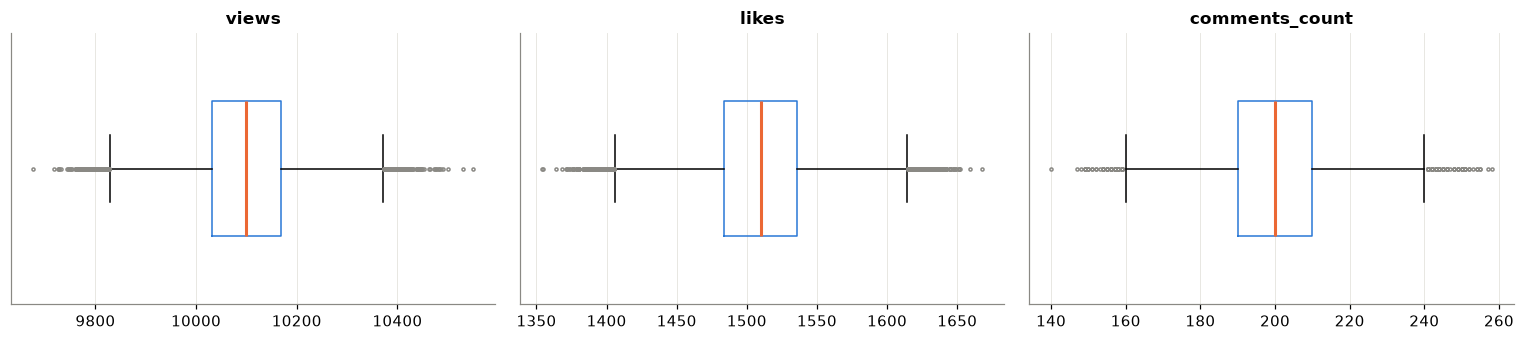

In [3]:
display(cleaning.outlier_report(df, TARGETS + ["follower_count", "content_length"]).round(1))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, t in zip(axes, TARGETS):
    ax.boxplot(df[t], vert=False, widths=0.5, flierprops={"markersize": 2, "markeredgecolor": plots.GRAY},
               medianprops={"color": plots.ORANGE, "linewidth": 2}, boxprops={"color": plots.BLUE})
    ax.set_title(t); ax.set_yticks([])
fig.tight_layout(); plt.show()

**Leitura:** não há duplicados, valores impossíveis (likes > views, negativos) ou ids repetidos. Os únicos nulos estão em `hashtags` (17%, = post sem hashtag, tratado como 0). `comments_text` vazio (17%) virou texto vazio.
Os "outliers" de Tukey (< 1% dos posts) ficam a no máximo +4,5% (views), +10% (likes) e +29% (comentários) da mediana. Um post viral real costuma ter 10–100x a mediana: aqui não há virais nem fracassos. **Nenhuma linha precisa ser removida.**
A audiência (gênero, idade e país predominantes) foi tratada como pré-publicação, porque vem do analytics do creator.

## 2. Variáveis-alvo

,média,mediana,p1,p10,p90,p99,desvio,CV (desvio/média),assimetria,curtose
views,10100.2830,10100.0000,9867.1300,9973.0000,10228.0000,10335.0000,100.0260,0.0100,0.0200,0.0130
likes,1510.2740,1510.0000,1420.0000,1461.0000,1560.0000,1602.0000,38.9200,0.0260,0.0280,0.0230
comments_count,200.0150,200.0000,168.0000,182.0000,218.0000,233.0000,14.0940,0.0700,0.0440,-0.0280


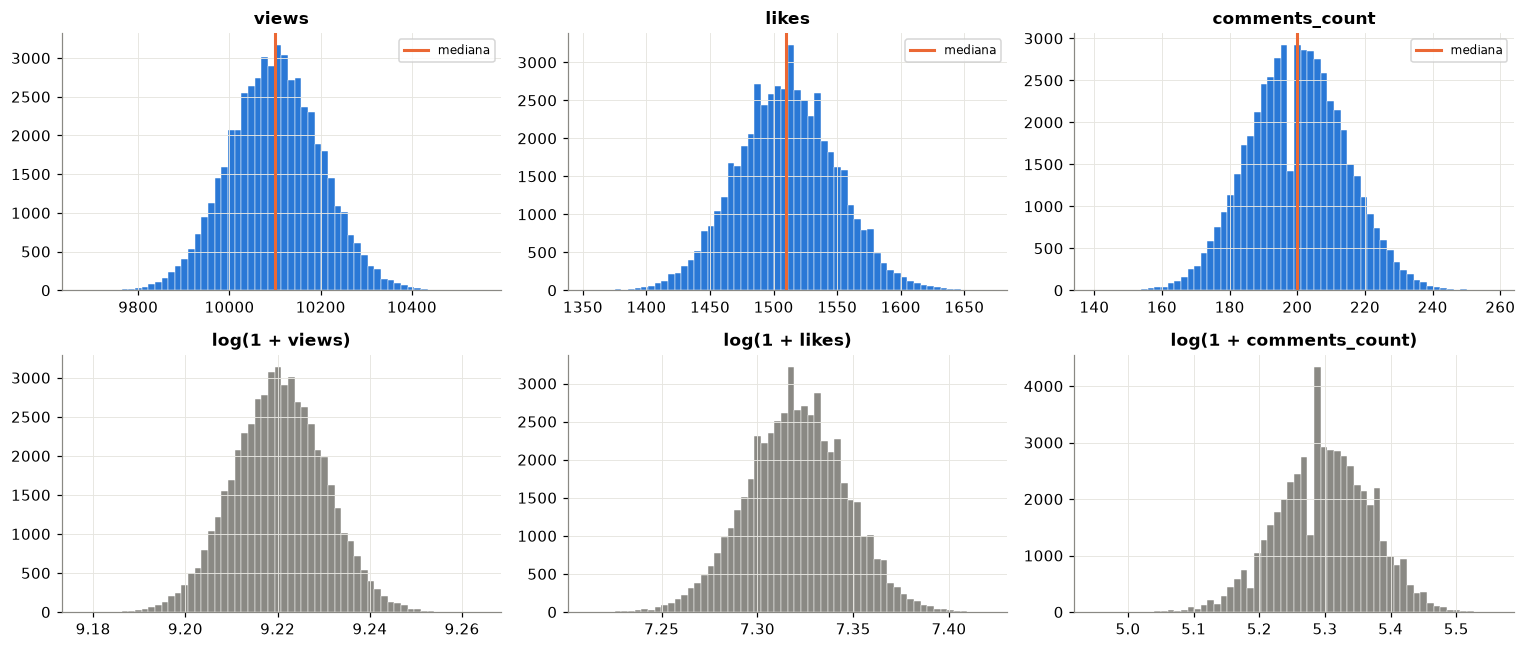

In [4]:
display(cleaning.target_profile(df, TARGETS).round(3))
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, t in enumerate(TARGETS):
    axes[0, j].hist(df[t], bins=60, color=plots.BLUE, edgecolor="white", linewidth=0.3); axes[0, j].set_title(f"{t}")
    axes[1, j].hist(np.log1p(df[t]), bins=60, color=plots.GRAY, edgecolor="white", linewidth=0.3); axes[1, j].set_title(f"log(1 + {t})")
    axes[0, j].axvline(df[t].median(), color=plots.ORANGE, linewidth=2, label="mediana"); axes[0, j].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Leitura:** assimetria ≈ 0 e média = mediana. As distribuições são sinos estreitos (CV de 1% em views, 3% em likes, 7% em comentários), sem a cauda longa típica de redes sociais.
**A transformação log não é necessária** (não muda a forma). Ela é mantida nos modelos só por padronização: com dados reais, que são assimétricos, ela será essencial.

## 3. Métricas normalizadas

,count,mean,std,min,10%,50%,90%,max
like_rate,52214.0000,0.1495,0.0041,0.1335,0.1443,0.1495,0.1548,0.1662
comment_rate,52214.0000,0.0198,0.0014,0.0140,0.0180,0.0198,0.0216,0.0262
likes_per_follower,52214.0000,0.0104,0.0460,0.0014,0.0017,0.0030,0.0150,1.5163
views_per_follower,52214.0000,0.0693,0.3070,0.0098,0.0112,0.0203,0.1001,10.1510


**Armadilha das razões:** dividir por seguidores cria correlação com seguidores, mesmo quando o numerador é aleatório.

,Spearman ρ
likes/seguidor × seguidores,-0.9990
likes EMBARALHADOS/seguidor × seguidores,-0.9990
likes × seguidores,-0.0040


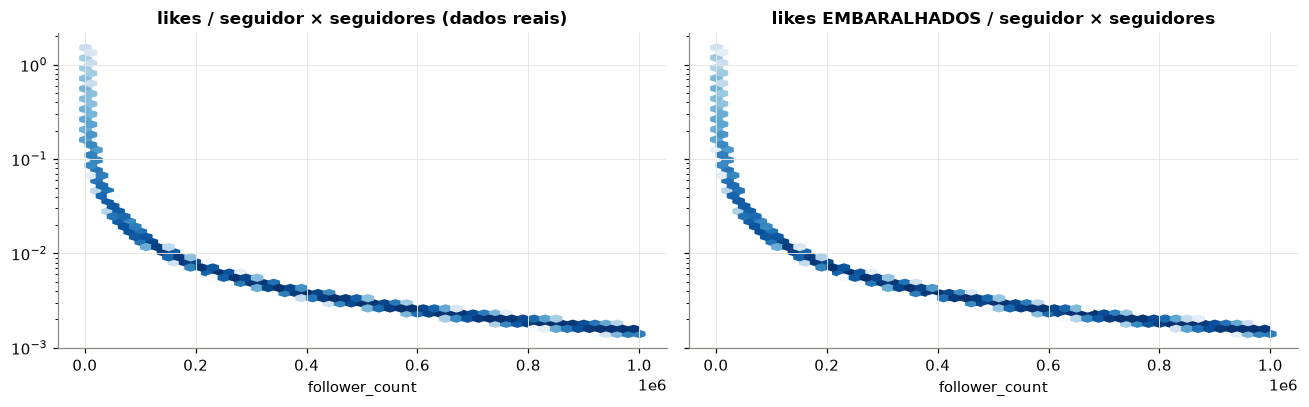

In [5]:
RATES = ["like_rate", "comment_rate", "likes_per_follower", "views_per_follower"]
display(df[RATES].describe(percentiles=[0.1, 0.5, 0.9]).T)
display(Markdown("**Armadilha das razões:** dividir por seguidores cria correlação com seguidores, mesmo quando o numerador é aleatório."))
display(ex.spurious_ratio_demo(df).round(3))

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
axes[0].hexbin(df.follower_count, df.likes_per_follower, gridsize=50, bins="log", yscale="log", cmap="Blues")
axes[0].set_title("likes / seguidor × seguidores (dados reais)")
axes[1].hexbin(df.follower_count, rng.permutation(df.likes.values) / df.follower_count, gridsize=50, bins="log", yscale="log", cmap="Blues")
axes[1].set_title("likes EMBARALHADOS / seguidor × seguidores")
for ax in axes: ax.set_xlabel("follower_count")
fig.tight_layout(); plt.show()

**Leitura:** "likes por seguidor" cai com o número de seguidores (ρ = −1,00), e cai igual com likes embaralhados. É **artefato matemático**, não "creators pequenos engajam mais".
O que de fato importa, likes × seguidores, dá ρ ≈ 0: **seguidores não aumentam likes nem views neste dataset.** As taxas por view (like rate, comment rate) são estáveis (~15% e ~2%).

## 4. Correlações numéricas (Pearson e Spearman)

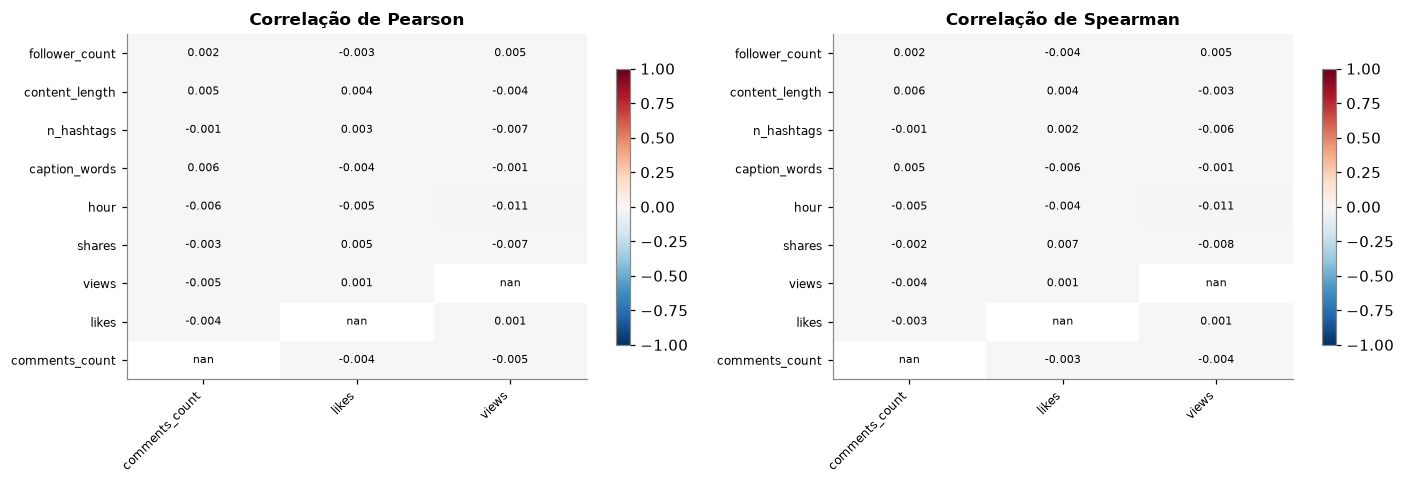

**Correlações significativas (Spearman, FDR):** 0 de 24 · maior |ρ|: 0.011

,alvo,variável,pearson,p_pearson,spearman,p_spearman,q_spearman
4,views,hour,-0.0112,0.0107,-0.0107,0.0147,0.3520
5,views,shares,-0.0074,0.0897,-0.0075,0.0852,0.6574
13,likes,shares,0.0053,0.2301,0.0069,0.1142,0.6574
17,comments_count,content_length,0.0050,0.2567,0.0064,0.1443,0.6574
2,views,n_hashtags,-0.0071,0.1025,-0.0062,0.1584,0.6574
11,likes,caption_words,-0.0040,0.3604,-0.0057,0.1905,0.6574


In [6]:
NUM_FEATURES = cleaning.PRE_PUBLICATION["numeric"] + ["shares"] + [m for m in TARGETS]
corr = ex.correlations(df, NUM_FEATURES, TARGETS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    plots.heatmap(ax, corr.pivot(index="variável", columns="alvo", values=method).loc[[f for f in NUM_FEATURES]],
                  f"Correlação de {method.title()}", vmin=-1, vmax=1, fmt="{:.3f}")
fig.tight_layout(); plt.show()
display(Markdown(f"**Correlações significativas (Spearman, FDR):** {int((corr.q_spearman < 0.05).sum())} de {len(corr)} · maior |ρ|: {corr.spearman.abs().max():.3f}"))
corr.sort_values("spearman", key=abs, ascending=False).head(6).round(4)

**Leitura:** todas as correlações têm |ρ| ≤ 0,011. Pearson e Spearman concordam, então não há relação monotônica nem linear.
A maior delas (horário × views, ρ = −0,011, p = 0,015) não sobrevive à correção (q = 0,35) e equivale a ~1 view a menos por hora do dia.
Nem as métricas se relacionam entre si: um post com mais views **não** tem mais likes. Isso é incomum em dados reais e indica que cada métrica foi sorteada de forma independente.

## 5. Variáveis categóricas (mediana, distribuição e testes)

In [7]:
CAT_FEATURES = ["platform", "content_type", "content_category", "language", "weekday", "daypart", "follower_tier",
                "is_sponsored", "sponsor_category", "disclosure_type", "audience_gender_distribution",
                "audience_age_distribution", "audience_location"]
tests = ex.categorical_tests(df, CAT_FEATURES, TARGETS)
display(Markdown(f"**{len(tests)} testes Kruskal-Wallis · significativos após FDR: {int(tests.significativo.sum())} · maior ε²: {tests['epsilon²'].max():.5f}** (0,01 já seria efeito pequeno)"))
tests.head(8).round(5)

**39 testes Kruskal-Wallis · significativos após FDR: 0 · maior ε²: 0.00025** (0,01 já seria efeito pequeno)

,variável,alvo,H,p_value,epsilon²,q_value,significativo
0,weekday,comments_count,13.2876,0.0387,0.0003,0.5030,False
1,daypart,views,10.6208,0.0140,0.0002,0.5030,False
2,language,likes,9.3232,0.0535,0.0002,0.5217,False
3,daypart,likes,8.5756,0.0355,0.0002,0.5030,False
4,audience_location,views,8.4199,0.2970,0.0002,0.9093,False
5,audience_location,likes,8.0704,0.3264,0.0001,0.9093,False
6,platform,likes,7.6426,0.1056,0.0001,0.8235,False
7,sponsor_category,likes,6.9418,0.3263,0.0001,0.9093,False


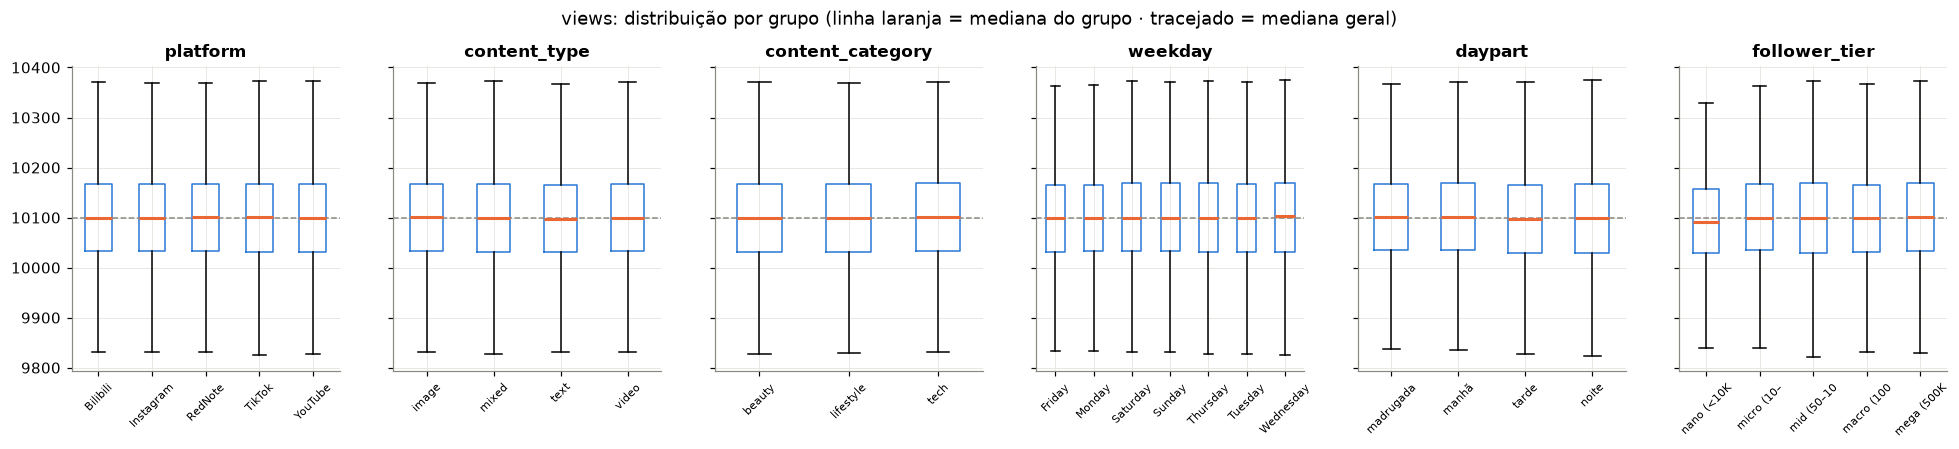

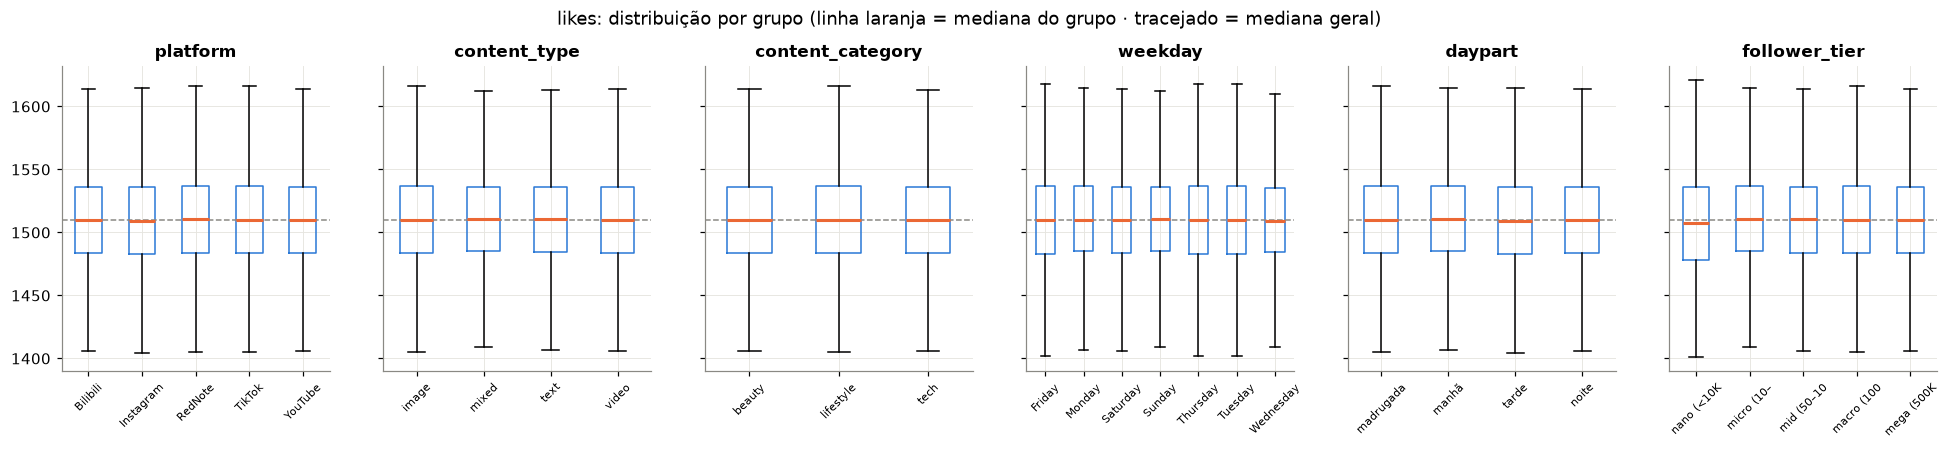

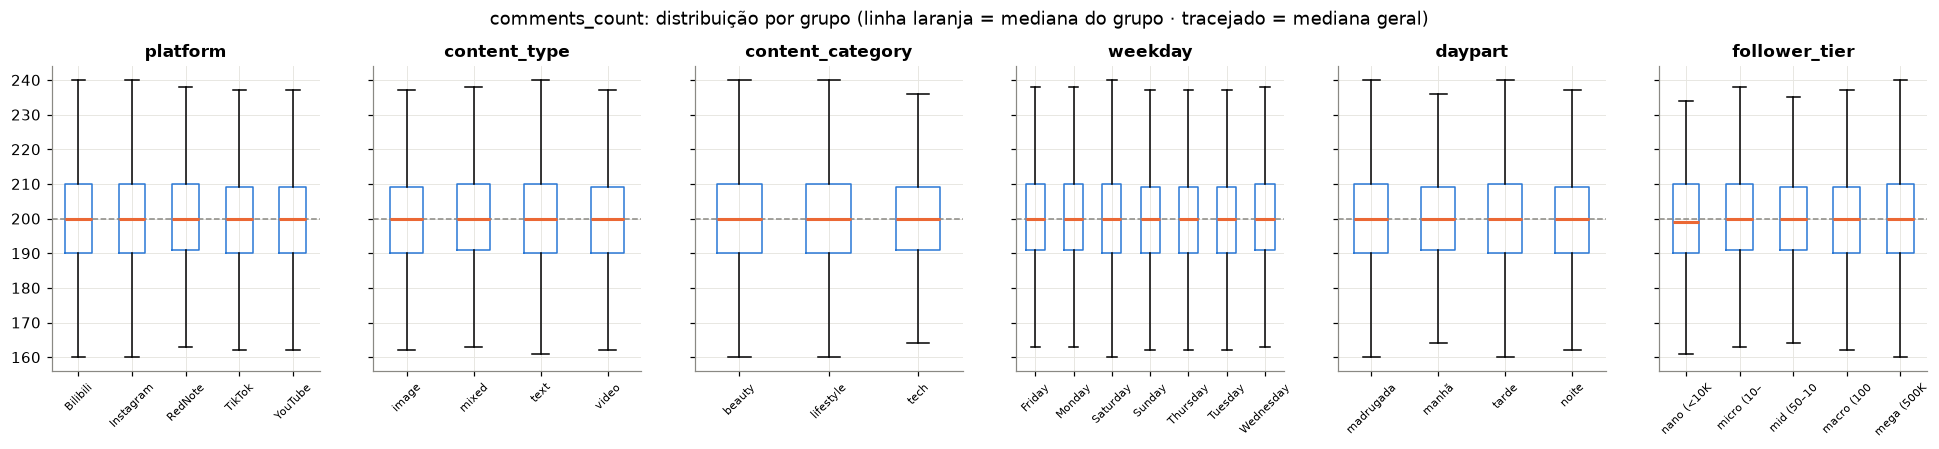

In [8]:
SHOW = ["platform", "content_type", "content_category", "weekday", "daypart", "follower_tier"]
for t in TARGETS:
    fig, axes = plt.subplots(1, len(SHOW), figsize=(22, 3.6), sharey=True)
    for ax, f in zip(axes, SHOW):
        groups = [(str(k), g.values) for k, g in df.groupby(f, observed=True)[t]]
        ax.boxplot([g for _, g in groups], tick_labels=[k[:10] for k, _ in groups], widths=0.5, showfliers=False,
                   medianprops={"color": plots.ORANGE, "linewidth": 2}, boxprops={"color": plots.BLUE})
        ax.axhline(df[t].median(), color=plots.GRAY, linestyle="--", linewidth=1)
        ax.set_title(f); ax.tick_params(axis="x", rotation=45, labelsize=7)
    fig.suptitle(f"{t}: distribuição por grupo (linha laranja = mediana do grupo · tracejado = mediana geral)", y=1.02)
    plt.show()

In [9]:
display(Markdown("**Mediana por grupo indexada (100 = post típico) — views:**"))
pd.concat({f: ex.group_stats(df, f, "views")["índice mediana"] for f in SHOW}).to_frame().T.round(2)

**Mediana por grupo indexada (100 = post típico) — views:**

platform                                     content_type  \
               Bilibili Instagram  RedNote   TikTok YouTube        image   
índice mediana 100.0000  100.0000 100.0100 100.0100 99.9900     100.0100   

                                         content_category  ...   weekday  \
                  mixed    text    video           beauty  ... Wednesday   
índice mediana 100.0000 99.9700 100.0000         100.0000  ...  100.0300   

                 daypart                          follower_tier  \
               madrugada    manhã   tarde   noite   nano (<10K)   
índice mediana  100.0100 100.0200 99.9800 99.9900       99.9100   

                                                                           
               micro (10–50K) mid (50–100K) macro (100–500K) mega (500K+)  
índice mediana       100.0000       99.9900         100.0000     100.0100  

[1 rows x 28 columns]

**Leitura:** as caixas (25–75%) são idênticas em todo grupo e as medianas ficam a ±0,2% do post típico. Nenhum teste é significativo e ε² ≈ 0.

## 6. Relações não lineares (faixas)

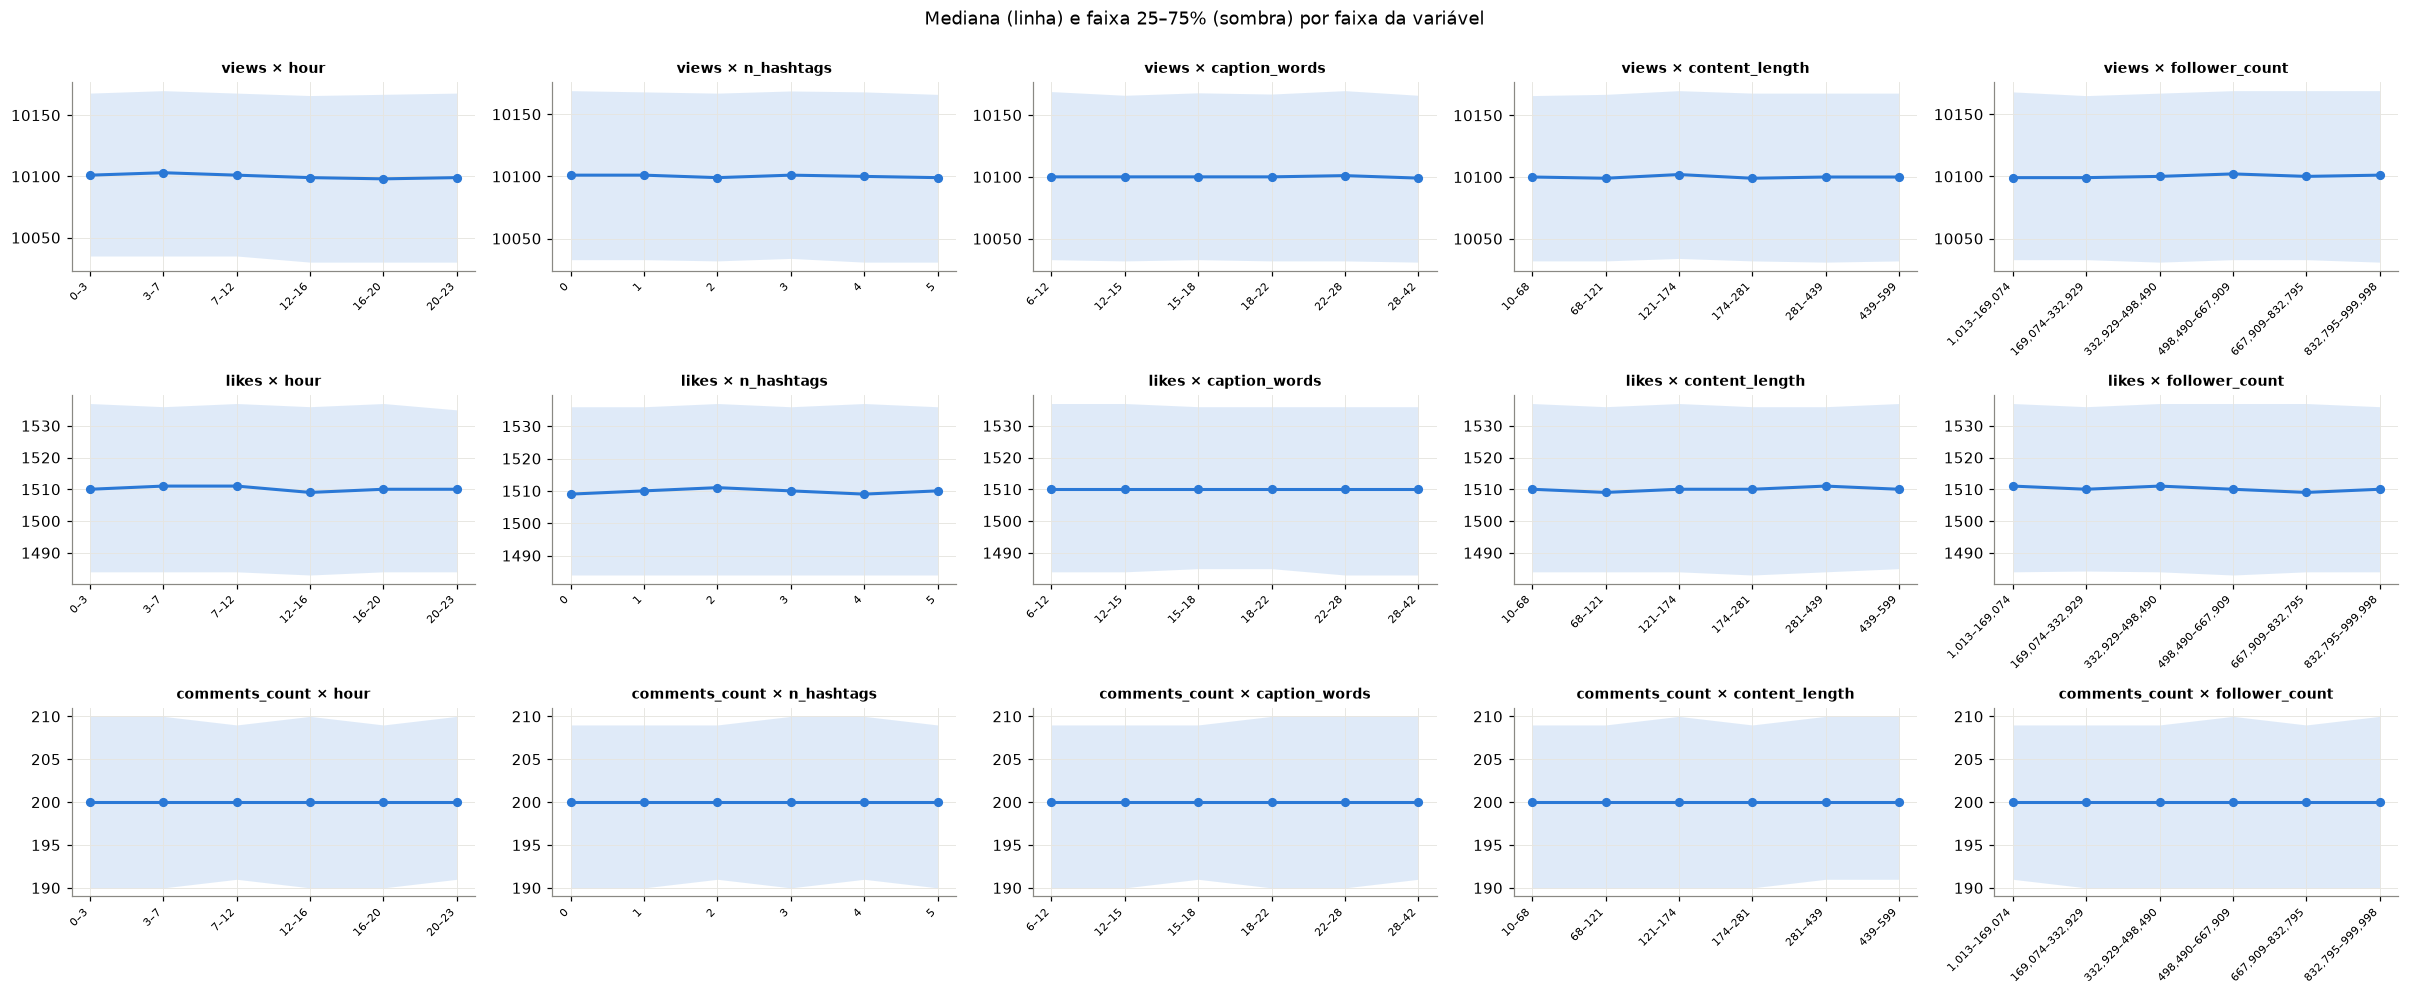

Kruskal p,caption_words,content_length,follower_count,hour,n_hashtags
alvo,,,,,
comments_count,0.6130,0.5450,0.3500,0.4740,0.8610
likes,0.8300,0.7420,0.8720,0.0910,0.7320
views,0.7230,0.6230,0.6720,0.0450,0.5920


In [10]:
BINNED = ["hour", "n_hashtags", "caption_words", "content_length", "follower_count"]
fig, axes = plt.subplots(len(TARGETS), len(BINNED), figsize=(22, 9))
pvals = {}
for i, t in enumerate(TARGETS):
    for j, f in enumerate(BINNED):
        bins = ex.bin_series(df[f], n_bins=6)
        order = df.groupby(bins)[f].median().sort_values().index
        g = df.groupby(bins)[t].describe(percentiles=[0.25, 0.5, 0.75]).loc[order]
        ax = axes[i, j]
        ax.fill_between(range(len(g)), g["25%"], g["75%"], color=plots.BLUE, alpha=0.15, linewidth=0)
        ax.plot(range(len(g)), g["50%"], "o-", color=plots.BLUE, linewidth=2, markersize=5)
        ax.set_xticks(range(len(g)), order, rotation=45, ha="right", fontsize=7)
        ax.set_title(f"{t} × {f}", fontsize=9)
        pvals[(t, f)] = ex.kruskal_effect(df.assign(_bin=bins), "_bin", t)["p_value"]
fig.suptitle("Mediana (linha) e faixa 25–75% (sombra) por faixa da variável", y=1.0)
fig.tight_layout(); plt.show()
pd.Series(pvals).unstack().round(3).rename_axis(index="alvo", columns="Kruskal p")

**Leitura:** as medianas são planas em todas as faixas de horário, hashtags, tamanho da legenda, duração e seguidores. Não há ponto ótimo (ex.: "3 hashtags" ou "30–60s").
Único p < 0,05: horário × views (p = 0,045), 1 de 15 testes, que é o esperado por acaso. A diferença entre a melhor e a pior faixa é de ~5 views em 10.100 (0,05%).

## 7. Top 10% × demais 90%

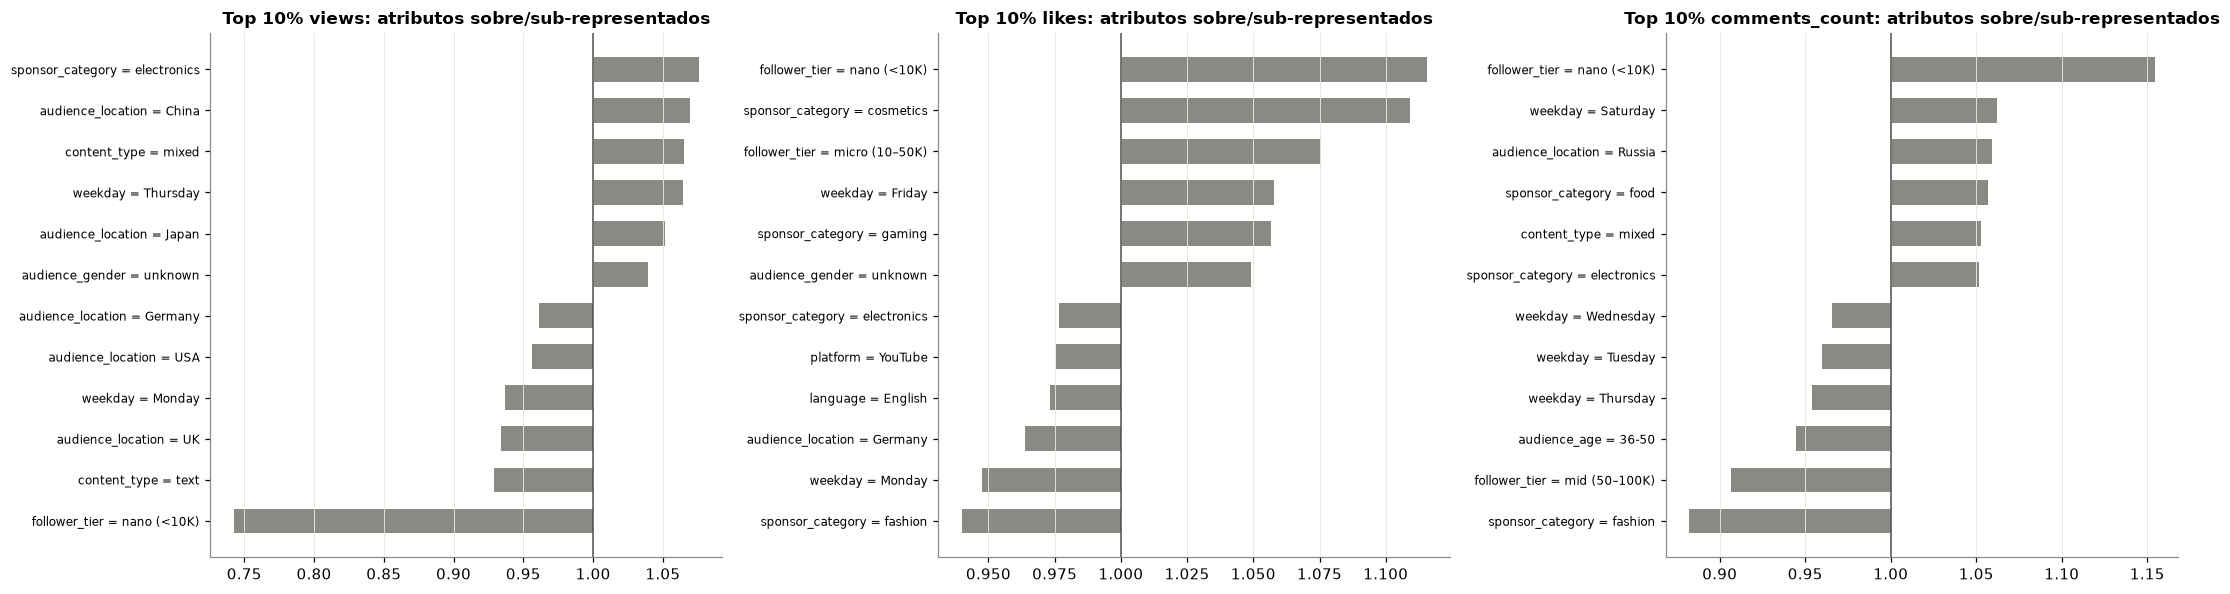

,atributos testados,"p<0,05 cru",esperado por acaso,significativos (FDR)
views,62.0000,7.0000,3.1000,0.0000
likes,62.0000,2.0000,3.1000,0.0000
comments_count,62.0000,3.0000,3.1000,0.0000


**Variáveis numéricas — top vs. demais (rank-biserial: 0 = sem diferença, ±0,1 = pequeno):**

mediana top  mediana demais  p_value  \
               variável                                               
views          follower_count  509524.0000     497126.0000   0.2580   
               content_length     175.0000        174.0000   0.7899   
               n_hashtags           2.0000          2.0000   0.2955   
               caption_words       18.0000         18.0000   0.5907   
               hour                12.0000         11.0000   0.4879   
likes          follower_count  503269.0000     498096.0000   0.7457   
               content_length     176.0000        174.0000   0.3212   
               n_hashtags           2.0000          2.0000   0.4544   
               caption_words       18.0000         18.0000   0.8531   
               hour                11.0000         12.0000   0.9206   
comments_count follower_count  504999.0000     497473.0000   0.1992   
               content_length     175.0000        174.0000   0.3180   
               n_hashtags           2.0000          2.0000   0.2326   
               caption_words       19.0000         18.0000   0.1188   
               hour                11.0000         12.0000   0.0178   

                               efeito (rank-biserial)  q_value  
               variável                                         
views          follower_count                  0.0095   0.7384  
               content_length                  0.0022   0.7899  
               n_hashtags                     -0.0087   0.7384  
               caption_words                   0.0045   0.7384  
               hour                            0.0058   0.7384  
likes          follower_count                 -0.0027   0.9206  
               content_length                  0.0083   0.9206  
               n_hashtags                      0.0061   0.9206  
               caption_words                  -0.0015   0.9206  
               hour                            0.0008   0.9206  
comments_count follower_count                  0.0104   0.2907  
               content_length                  0.0081   0.3180  
               n_hashtags                     -0.0096   0.2907  
               caption_words                   0.0127   0.2907  
               hour                           -0.0192   0.0892

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
summary = {}
for ax, t in zip(axes, TARGETS):
    lifts = tp.lift_table(df, TOPS[t], CAT_FEATURES)
    plots.lift_bars(ax, lifts, f"Top 10% {t}: atributos sobre/sub-representados")
    summary[t] = {"atributos testados": len(lifts), "p<0,05 cru": int((lifts.p_value < 0.05).sum()),
                  "esperado por acaso": tp.expected_false_positives(lifts), "significativos (FDR)": int(lifts.significant.sum())}
fig.tight_layout(); plt.show()
display(pd.DataFrame(summary).T)
display(Markdown("**Variáveis numéricas — top vs. demais (rank-biserial: 0 = sem diferença, ±0,1 = pequeno):**"))
pd.concat({t: ex.compare_numeric(df, TOPS[t], cleaning.PRE_PUBLICATION["numeric"]).set_index("variável") for t in TARGETS}).round(4)

**Leitura:** os tops têm o mesmo perfil dos demais: mesma mediana de seguidores, duração, hashtags, legenda e horário (efeitos < 0,02). Os atributos "a mais" ficam dentro do acaso.

## 8–9. Modelos preditivos × dois cenários

R² treino                       R² validação  \
modelo                         CatBoost Random Forest XGBoost     CatBoost   
alvo           cenário                                                       
comments_count explicativo       0.0101        0.1204  0.0638      -0.0010   
               pré-publicação    0.0045        0.0929  0.0582      -0.0007   
likes          explicativo       0.0092        0.1200  0.0622      -0.0014   
               pré-publicação    0.0051        0.0932  0.0586      -0.0007   
views          explicativo       0.0114        0.1197  0.0632      -0.0012   
               pré-publicação    0.0063        0.0926  0.0590      -0.0011   

                                                     
modelo                        Random Forest XGBoost  
alvo           cenário                               
comments_count explicativo          -0.0033 -0.0085  
               pré-publicação       -0.0038 -0.0085  
likes          explicativo          -0.0025 -0.0075  
               pré-publicação       -0.0020 -0.0060  
views          explicativo          -0.0033 -0.0079  
               pré-publicação       -0.0034 -0.0074

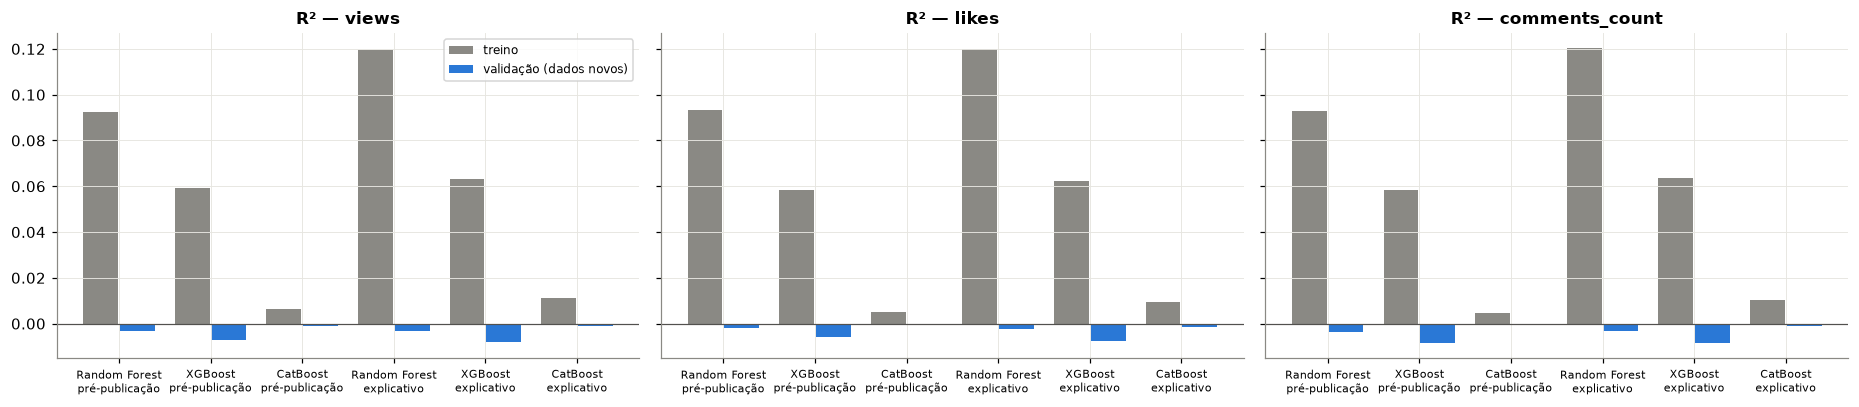

In [12]:
MODELS = ["Random Forest", "XGBoost", "CatBoost"]
SCENARIOS = ["pré-publicação", "explicativo"]
results = pd.DataFrame([mo.cross_validate(df, t, s, m, data.METRICS) for t in TARGETS for s in SCENARIOS for m in MODELS])
display(results.pivot_table(index=["alvo", "cenário"], columns="modelo", values=["R² treino", "R² validação"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, t in zip(axes, TARGETS):
    r = results[results.alvo == t].reset_index(drop=True)
    labels = r.modelo + "\n" + r.cenário
    x = np.arange(len(r))
    ax.bar(x - 0.2, r["R² treino"], width=0.38, color=plots.GRAY, label="treino")
    ax.bar(x + 0.2, r["R² validação"], width=0.38, color=plots.BLUE, label="validação (dados novos)")
    ax.set_xticks(x, labels, fontsize=7); ax.axhline(0, color=plots.INK, linewidth=0.8); ax.set_title(f"R² — {t}")
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Leitura:**
- **Pré-publicação:** R² de validação ≈ 0 nos 3 modelos e nos 3 alvos. Nada do que se sabe antes de postar prevê o resultado.
- **Explicativo** (com as outras métricas): também ≈ 0. Saber as views **não ajuda** a prever likes ou comentários, o que confirma as métricas independentes.
- O Random Forest chega a R² ~0,1 no treino e ≈ 0 na validação: **ele decora ruído**. Sem validação em dados novos, esse modelo seria vendido como "explica 10% dos likes".

## 10. Interpretação (feature importance, SHAP, interações)

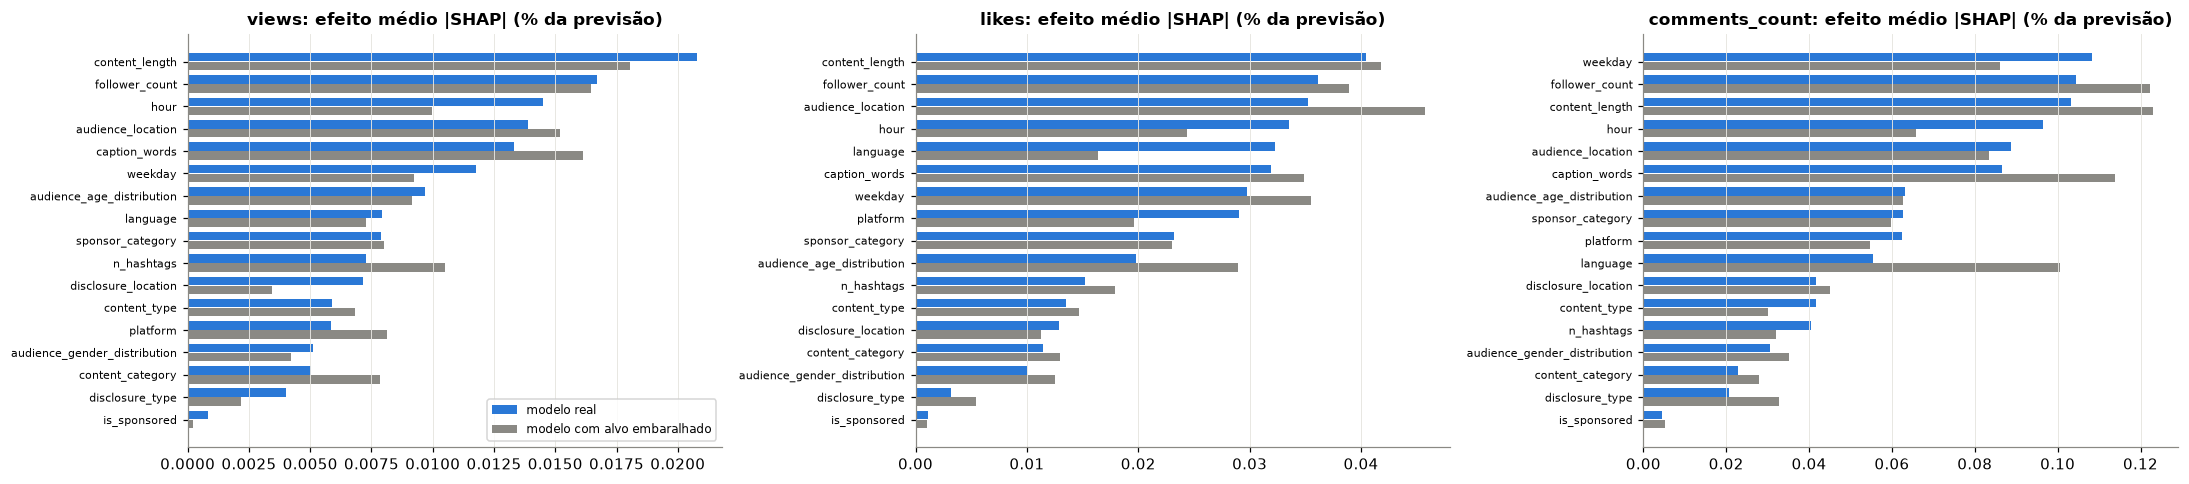

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
SHAP = {}
for ax, t in zip(axes, TARGETS):
    model, X = mo.fit_xgb(df, t, "pré-publicação", data.METRICS)
    null_model, X0 = mo.fit_xgb(df, t, "pré-publicação", data.METRICS, shuffle_target=True)
    values, sample = mo.shap_values(model, X)
    SHAP[t] = (model, X, values, sample)
    real = mo.shap_importance(values, sample).set_index("variável")["efeito médio (%)"]
    null = mo.shap_importance(*mo.shap_values(null_model, X0)).set_index("variável")["efeito médio (%)"].reindex(real.index)
    y = np.arange(len(real))[::-1]
    ax.barh(y + 0.2, real.values, height=0.38, color=plots.BLUE, label="modelo real")
    ax.barh(y - 0.2, null.values, height=0.38, color=plots.GRAY, label="modelo com alvo embaralhado")
    ax.set_yticks(y, real.index, fontsize=7); ax.set_title(f"{t}: efeito médio |SHAP| (% da previsão)"); ax.grid(axis="y", visible=False)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

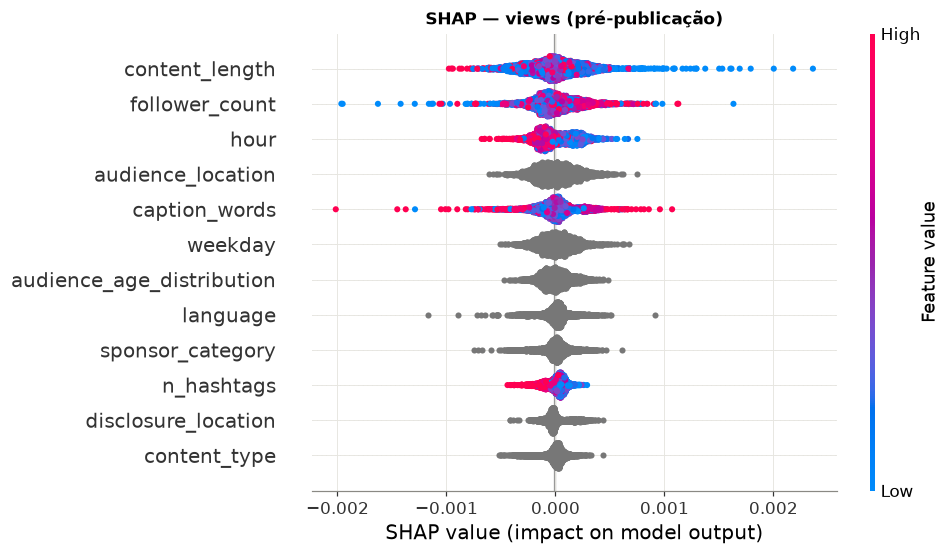

**Quais valores aumentam (+) ou reduzem (−) a previsão de views?** (efeito em % da previsão)

,variável,valor,efeito (%)
36,disclosure_location,caption,0.0177
44,audience_age_distribution,13-18,0.0173
51,audience_location,Germany,0.0169
16,language,Spanish,0.0167
50,audience_location,China,0.0164
15,language,Japanese,-0.0253
7,content_type,text,-0.0185
27,sponsor_category,cosmetics,-0.0169
49,audience_location,Brazil,-0.0149
54,audience_location,Russia,-0.0137


**Interações mais fortes (SHAP interaction values):**

,par,interação média (%)
0,weekday × follower_count,0.0085
1,audience_location × follower_count,0.0075
2,weekday × content_length,0.0070
3,follower_count × hour,0.0067
4,weekday × hour,0.0066
5,audience_age_distribution × follower_count,0.0066
6,follower_count × content_length,0.0060
7,audience_location × caption_words,0.0053


In [14]:
model, X, values, sample = SHAP["views"]
shap.summary_plot(values, sample, max_display=12, show=False, plot_size=(9, 5))
plt.title("SHAP — views (pré-publicação)"); plt.show()
display(Markdown("**Quais valores aumentam (+) ou reduzem (−) a previsão de views?** (efeito em % da previsão)"))
display(mo.shap_direction(values, sample, top_n=5).round(4))
display(Markdown("**Interações mais fortes (SHAP interaction values):**"))
mo.shap_interactions(model, X, top_n=8).round(4)

In [15]:
display(Markdown("**Cenário explicativo — likes: as views ajudam?**"))
m_exp, X_exp = mo.fit_xgb(df, "likes", "explicativo", data.METRICS)
mo.shap_importance(*mo.shap_values(m_exp, X_exp)).head(8).round(4)

**Cenário explicativo — likes: as views ajudam?**

,variável,mean |SHAP| (log),efeito médio (%)
0,audience_location,0.0003,0.0326
1,shares,0.0003,0.0310
2,language,0.0003,0.0304
3,content_length,0.0003,0.0296
4,follower_count,0.0003,0.0293
5,platform,0.0003,0.0276
6,hour,0.0003,0.0267
7,weekday,0.0003,0.0259


**Leitura:** as maiores importâncias SHAP equivalem a 0,02% (views), 0,04% (likes) e 0,12% (comentários) da previsão. Um modelo treinado com o alvo **embaralhado** dá importâncias do mesmo tamanho e às vezes maiores (barras cinza).
Ou seja, os rankings de importância são ruído do modelo e **não devem ser lidos como "fator mais importante"**. As interações também ficam em ~0,01%. No cenário explicativo, as views não aparecem acima do resto.

## 11. Resultado

### 11.1 Principais relações e fatores associados
| Pergunta | Resposta | Evidência |
|---|---|---|
| O que está associado a mais **views**? | Nenhuma variável disponível | §4 ρ < 0,01 · §5 0 testes significativos · §8 R² ≈ 0 |
| E a mais **likes**? | Nenhuma; nem as views | §4, §9 (explicativo R² ≈ 0) |
| E a mais **comentários**? | Nenhuma | §4–§10 |
| Seguidores importam? | Não (ρ ≈ 0). "Likes por seguidor" engana | §3 |
| Top 10% é diferente dos 90%? | Não: mesmo formato, tema, horário, hashtags, audiência | §7 |
| Há efeitos não lineares ou interações? | Não: faixas planas, interações SHAP ~0,01% | §6, §10 |

### 11.2 Recomendações práticas (com o que os dados permitem afirmar)
| Fator controlável | Recomendação | Por quê |
|---|---|---|
| **Formato** (vídeo/imagem/texto) | Escolher pelo **custo de produção**, não pelo alcance esperado | Mediana igual em todo formato (§5) |
| **Tema** (beauty/lifestyle/tech) | Escolher por **estratégia de marca** | Nenhuma diferença (§5, §7) |
| **Horário/dia** | Postar quando for **operacionalmente mais barato** e parar de pagar por "horário nobre" | Curvas planas (§6) |
| **Hashtags** | 0–5 hashtags rendem igual. Não investir tempo otimizando | §6 |
| **Tamanho do creator** | Não pagar prêmio por seguidores. Negociar por **custo por post** | ρ(seguidores, views) ≈ 0 (§3) |
| **Patrocínio** | Patrocinado = orgânico em todas as métricas, então **pagar não compra desempenho** | §5, §7 |
| **Processo** | Toda "receita vencedora" precisa passar por **teste A/B** antes de virar regra | §7–§10: padrões aparentes (lift 1,5x) somem com correção |

### 11.3 Correlação × causalidade
| O que os dados mostram | O que **não** mostram |
|---|---|
| Ausência de associação entre atributos e desempenho (dados observacionais) | Que mudar um atributo **causaria** mudança, em qualquer direção |
| Patrocinado ≈ orgânico em média | O efeito causal do patrocínio (a escolha de quem patrocinar não é aleatória) |
| Métricas independentes entre si | Que views não causam likes no mundo real. Isso é uma propriedade deste dataset (sintético) |

**Para afirmar causalidade:** teste A/B (mesmo creator, mesmo período, variando um fator por vez) ou desenho quase-experimental (diferenças-em-diferenças em mudanças de política de postagem).

### 11.4 Limitação central
O dataset é sintético (ver `knowledge/dataset.md`): as métricas foram sorteadas de forma independente das características do post.
O pipeline foi validado com um efeito plantado de +2% (notebooks 02/03) e o detecta. **Rodando sobre os dados reais da empresa, as mesmas seções produzirão os fatores reais.**